# Q4 follow-up: the advisor's questions

Written 28 September 2026, after the meeting with the advisor. It follows on from
`q4_exploration.ipynb` and leaves that notebook untouched. It runs on its own: it reads the
saved CPI file and does not call the BLS API.

**Format:** the same as `q4_exploration`. **Q** is the question, **D** what was done,
**F** what was found, **W** the warning.

## Bottom line

| The advisor asked | Answer |
|---|---|
| Run HAC with a 12-month window | Done (A). It changes the standard errors by less than 10% and none of the conclusions. The problem is not the window. |
| Is 4 to 6 months too late? | Yes (B). The data does not support a 4 to 6 month delay. The correlation climbs steadily from lag 0 to lag 10 and never peaks in that window. |
| Could something else be interacting? | Yes (B and C). Activity jumped 20% in a single month, March 2023, which smoothly falling prices cannot explain. The SNAP benefit cut is recorded one month later. Adding SNAP lifts R² from 0.49 to 0.75 for households and cuts the price coefficient by about a third. |
| So when do prices act? | If they act, within about one month (D). That shows in pounds and individuals. The net effect over six months cannot be told apart from zero. |
| Redo the county split by metro | Done (E). The higher-cost group is mostly the metro counties. Once county size is removed, neither cost nor metro status makes a difference. |
| Does "households per food-insecure person" carry the Q1 caveat? | One of the two (F). The built-in tilt does not apply here. The county-size problem does. |

**The headline in `q4_exploration` should change.** "Demand rises about 4 to 6 months after
prices rise" is not supported. Section G has wording that is.

In [1]:
import sys
import warnings
from pathlib import Path

# find the repo root (the folder that contains src/), wherever this notebook is saved
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "qkit.py").exists())
sys.path.insert(0, str(ROOT / "src"))
warnings.simplefilter("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats as sp

import config as cfg
import qkit

METRICS = ["households", "pounds", "individuals"]
COLORS = {"households": "#2563eb", "pounds": "#f97316", "individuals": "#16a34a"}
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

In [2]:
# Activity: statewide monthly totals, food-shelf-like sites only (the same choice as q4_exploration)
cm = qkit.county_month(food_shelf_only=True)
qkit.leakage_check(cm)
st = (cm.groupby("date")
        .agg(**{m: (m, "sum") for m in METRICS}, n_sites=("n_sites_reporting", "sum"))
        .sort_index())

# Prices: read the saved file, so this notebook never calls the BLS API.
# reindex() keeps October 2025 as a gap instead of closing it up.
cpi = (pd.read_csv(cfg.EXTERNAL / "bls" / "CUUR0200SAF11.csv", parse_dates=["date"])
         .set_index("date")["value"])
cpi = cpi.reindex(pd.date_range(cpi.index.min(), "2026-07-01", freq="MS"))

# SNAP: statewide federal food benefits per case. Built by src/build_snap.py.
if not cfg.P_SNAP.exists():
    import build_snap
    build_snap.main()
snap = (qkit.snap(counties_only=False)
            .groupby("date")[["case_count", "snap_federal_food_issued"]].sum())
snap_benefit = snap["snap_federal_food_issued"] / snap["case_count"]

# Year-over-year change in everything
yoy = pd.concat([st[METRICS].pct_change(12, fill_method=None),
                 st["n_sites"].pct_change(12, fill_method=None).rename("sites"),
                 snap_benefit.pct_change(12).reindex(st.index).rename("snap")], axis=1)
cpi_yoy = cpi.pct_change(12, fill_method=None)


def data_at(lag):
    """The regression table with CPI shifted back by `lag` months."""
    d = yoy.join(cpi_yoy.shift(lag).rename("cpi"))
    d["trend"] = np.arange(len(d)) / 12          # years since January 2022
    return d.dropna()


def hac_fit(y, X, maxlags=12):
    """OLS with Newey-West (HAC) standard errors. maxlags is the width of the window."""
    return sm.OLS(y, sm.add_constant(X)).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags, "use_correction": True})


print(f"activity: {len(st)} months, {st.index.min():%Y-%m} to {st.index.max():%Y-%m}")
print(f"CPI gaps: {list(cpi[cpi.isna()].index.strftime('%Y-%m'))}")
print(f"rows available at lag 5: {len(data_at(5))}")
(snap_benefit.loc[["2023-03-01", "2023-04-01"]].rename("SNAP federal benefit per case, $")
             .round(0).to_frame())

leakage_check passed: nothing at or after 202608
leakage_check passed: nothing at or after 202608
activity: 55 months, 2022-01 to 2026-07
CPI gaps: ['2025-10']
rows available at lag 5: 42


,"SNAP federal benefit per case, $"
date,
2023-03-01,453.000
2023-04-01,267.000


## A. HAC standard errors with a 12-month window

**Q:** Step 10b used a 3-month window. Year-over-year changes overlap for 11 months, so
the errors stay correlated for much longer than 3. What happens with 12?

**D:** Refit the Step 10b model (activity YoY on lagged CPI YoY and sites YoY) at lags 0 to
10, with three kinds of standard error: HC1, HAC with 3 months, HAC with 12 months.

**How to run it.** The window is the `maxlags` value. Nothing else changes:

```python
sm.OLS(y, sm.add_constant(X)).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12, "use_correction": True})
```

`use_correction=True` applies a small-sample adjustment, which matters with 42 rows. The
helper `hac_fit(y, X, maxlags=12)` defined above does exactly this.

In [3]:
rows = []
for m in METRICS:
    for lag in range(0, 11):
        d = data_at(lag)
        X = d[["cpi", "sites"]]                      # the model from Step 10b
        hc1 = sm.OLS(d[m], sm.add_constant(X)).fit(cov_type="HC1")
        h3, h12 = hac_fit(d[m], X, maxlags=3), hac_fit(d[m], X, maxlags=12)
        rows.append({"metric": m, "lag": lag, "n": len(d), "coef": h12.params["cpi"],
                     "se_HC1": hc1.bse["cpi"], "se_HAC3": h3.bse["cpi"],
                     "se_HAC12": h12.bse["cpi"],
                     "p_HAC3": h3.pvalues["cpi"], "p_HAC12": h12.pvalues["cpi"]})
hac = pd.DataFrame(rows)
hac[hac["metric"] == "households"].drop(columns="metric").set_index("lag")

,n,coef,se_HC1,se_HAC3,se_HAC12,p_HAC3,p_HAC12
lag,,,,,,,
0,42,-2.299,2.194,1.832,1.726,0.210,0.183
1,42,-0.738,1.919,1.740,1.830,0.672,0.687
2,42,-0.174,1.894,1.735,1.808,0.920,0.923
3,42,2.113,1.723,1.615,1.523,0.191,0.165
4,42,4.180,1.253,1.029,0.768,0.000,0.000
5,42,4.713,0.832,0.902,0.877,0.000,0.000
6,42,4.702,0.632,0.821,0.806,0.000,0.000
7,42,4.194,0.566,0.722,0.752,0.000,0.000
8,42,3.944,0.459,0.544,0.602,0.000,0.000


In [4]:
# The same comparison at each metric's peak lag
peak = hac.loc[hac.groupby("metric")["coef"].idxmax()].set_index("metric")
peak[["lag", "coef", "se_HC1", "se_HAC3", "se_HAC12", "p_HAC12"]]

,lag,coef,se_HC1,se_HAC3,se_HAC12,p_HAC12
metric,,,,,,
households,5,4.713,0.832,0.902,0.877,0.000
individuals,6,5.390,0.728,0.857,0.873,0.000
pounds,5,3.517,0.688,0.695,0.731,0.000


**F:** Widening the window barely matters. For households at lag 5 the coefficient is 4.71
and the standard error is 0.83 (HC1), 0.90 (3 months) and 0.88 (12 months). Every p-value
at lags 4 to 10 is below 0.001 under all three. The coefficients match Step 10b exactly,
so this is the same model.

**W:** That does not make the result trustworthy. See the next table.

In [5]:
d = data_at(5)
auto = pd.DataFrame({
    "correlation with the month before": {c: d[c].autocorr(1) for c in METRICS + ["cpi", "sites", "snap"]},
})
auto.index = ["households YoY", "pounds YoY", "individuals YoY", "CPI YoY, lagged 5",
              "reporting sites YoY", "SNAP benefit YoY"]
auto

,correlation with the month before
households YoY,0.755
pounds YoY,0.771
individuals YoY,0.888
"CPI YoY, lagged 5",0.987
reporting sites YoY,0.916
SNAP benefit YoY,0.837


**F:** The lagged CPI series has a correlation of 0.987 with its own previous month. It is
one smooth decline, not 42 separate readings.

**W:** This is why no choice of window rescues the p-values. HAC corrects standard errors
for correlated errors. It cannot create information. With one decline in prices and one
decline in activity growth, there is in effect one observation of "prices fell, then
activity growth fell". A p-value below 0.001 from one observation is not evidence.

## B. Is the 4 to 6 month delay real?

**Q:** The advisor's point: 4 to 6 months is a long time for a household to react to a
grocery bill. Is the delay in the data, or is it produced by the method?

**D:** Two checks. First, plot every series in the model over time. Second, correlate
activity with prices at leads as well as lags. A lead means prices move *after* activity.
Prices cannot cause something that already happened, so if leads correlate too, the
correlation is not measuring a response.

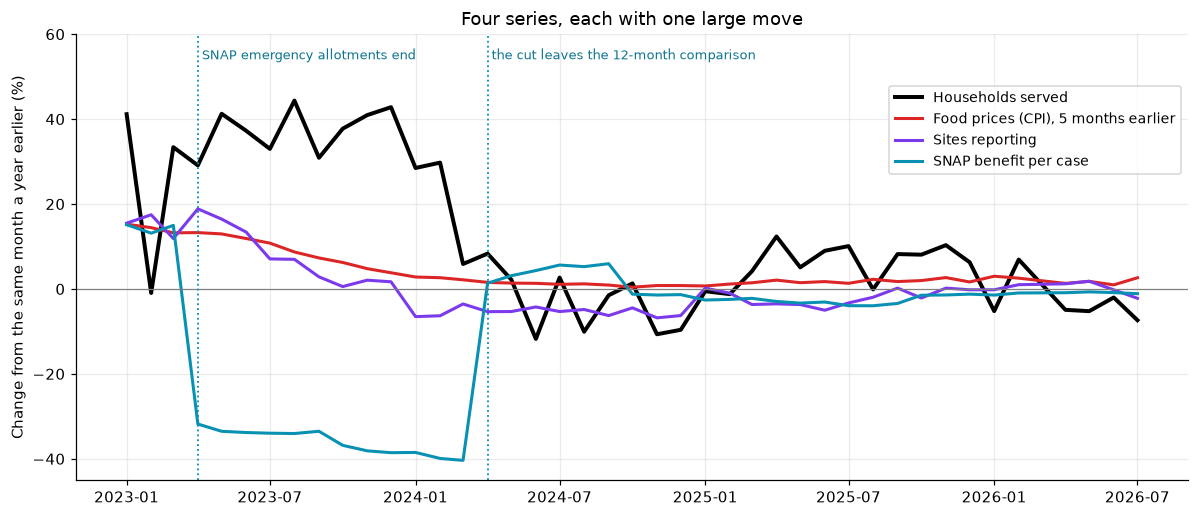

,households,cpi,sites,snap
date,,,,
2023-01-01,41.200,15.200,15.500,15.100
2023-04-01,29.100,13.300,18.900,-31.800
2023-07-01,33.000,10.800,7.100,-34.000
2023-10-01,37.700,6.200,0.600,-36.800
2024-01-01,28.500,2.800,-6.500,-38.500
2024-04-01,8.300,1.500,-5.400,1.400
2024-07-01,2.700,1.100,-5.300,5.600
2024-10-01,1.300,0.400,-4.500,-1.200
2025-01-01,-0.500,0.700,0.200,-2.600


In [6]:
d = data_at(5) * 100
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(d.index, d["households"], color="black", lw=2.6, label="Households served")
ax.plot(d.index, d["cpi"], color="#dc2626", lw=2, label="Food prices (CPI), 5 months earlier")
ax.plot(d.index, d["sites"], color="#7c3aed", lw=2, label="Sites reporting")
ax.plot(d.index, d["snap"], color="#0891b2", lw=2, label="SNAP benefit per case")
ax.axhline(0, color="grey", lw=0.8)
for when, text in [("2023-04-01", "SNAP emergency allotments end"),
                   ("2024-04-01", "the cut leaves the 12-month comparison")]:
    ax.axvline(pd.Timestamp(when), color="#0891b2", ls=":", lw=1.2)
    ax.text(pd.Timestamp(when), 55, " " + text, fontsize=8.5, color="#0e7490", va="center")
ax.set_ylim(-45, 60)
ax.set_ylabel("Change from the same month a year earlier (%)")
ax.set_title("Four series, each with one large move")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.9), fontsize=9)
plt.tight_layout()
plt.show()

d.iloc[::3][["households", "cpi", "sites", "snap"]].round(1)

In [7]:
d = data_at(5)
display(d[["cpi", "sites", "snap", "trend"]].corr().round(2))

# The spread of the CPI series grows with the lag, because longer lags reach back into 2022
pd.DataFrame({"standard deviation of lagged CPI YoY, points":
              {f"lag {k}": 100 * data_at(k)["cpi"].std() for k in (0, 5, 10)}}).round(2)

,cpi,sites,snap,trend
cpi,1.000,0.930,-0.240,-0.740
sites,0.930,1.000,-0.160,-0.540
snap,-0.240,-0.160,1.000,0.430
trend,-0.740,-0.540,0.430,1.000


,"standard deviation of lagged CPI YoY, points"
lag 0,2.590
lag 5,4.450
lag 10,5.240


**F:** Every series makes one large move and then goes flat.

- Household growth ran at about 30% to 45% through 2023, apart from one dip in February
  that Step 6 explains. It was still 30% in February 2024, and 6% a month later.
- Lagged food inflation fell steadily from 15% to about 1%.
- Growth in reporting sites fell from 19% to about minus 5%.
- The SNAP benefit per case is a block of about minus 35% that lasts 12 months.

Lagged CPI and sites growth have a correlation of **0.93**. The model in Step 10b has two
explanatory variables that are nearly the same series, so it cannot tell them apart.

The spread of the lagged CPI series also grows with the lag (2.6 points at lag 0, 5.2 at
lag 10), because longer lags reach back into 2022 when inflation was higher. That alone
changes the size of the coefficient from one lag to the next.

In [8]:
around = pd.concat([st[METRICS + ["n_sites"]],
                    snap_benefit.rename("SNAP benefit per case, $")], axis=1)
display(around.loc["2022-12-01":"2023-06-01"].round(0))

feb_to_mar = pd.DataFrame({
    year: 100 * (st.loc[f"{year}-03-01", METRICS] / st.loc[f"{year}-02-01", METRICS] - 1)
    for year in range(2022, 2027)}).T
feb_to_mar.index.name = "change from February to March, %"
display(feb_to_mar.round(1))

(100 * yoy.loc["2023-12-01":"2024-05-01", METRICS + ["snap"]]).round(1)

,households,pounds,individuals,n_sites,"SNAP benefit per case, $"
date,,,,,
2022-12-01,"149,284.000","9,783,245.000","456,293.000",533.000,447.000
2023-01-01,"163,088.000","9,946,614.000","500,377.000",537.000,442.000
2023-02-01,"156,066.000","9,089,588.000","478,476.000",538.000,450.000
2023-03-01,"187,054.000","11,083,405.000","584,995.000",537.000,453.000
2023-04-01,"185,201.000","10,295,697.000","574,599.000",542.000,267.000
2023-05-01,"197,339.000","11,371,088.000","605,018.000",545.000,262.000
2023-06-01,"213,532.000","11,794,747.000","653,149.000",542.000,259.000


,households,pounds,individuals
"change from February to March, %",,,
2022,-11.000,23.700,27.200
2023,19.900,21.900,22.300
2024,-2.200,-1.900,-2.300
2025,3.100,6.100,2.400
2026,5.600,2.900,4.900


,households,pounds,individuals,snap
date,,,,
2023-12-01,42.800,20.400,43.800,-38.600
2024-01-01,28.500,17.400,31.100,-38.500
2024-02-01,29.700,21.100,30.500,-39.900
2024-03-01,5.900,-2.600,4.200,-40.400
2024-04-01,8.300,10.400,8.300,1.400
2024-05-01,2.200,0.700,5.300,3.100


**F:** The largest single move in the data is a jump in **March 2023**.

| February to March 2023 | households | pounds | individuals |
|---|---|---|---|
| Change in one month | +19.9% | +21.9% | +22.3% |

Activity stayed at the new level. The number of reporting sites did not change (537 to
542), so this is more activity at the same sites. In 2024, 2025 and 2026 the change from
February to March was between minus 2% and plus 6%.

A one-time jump shows up in year-over-year data as 12 months of high growth that then
stops. That is the shape in the chart: growth falls from 30% to 6% in March 2024, exactly
12 months later.

**Prices cannot produce that shape.** Food inflation fell smoothly over two years. A step
in one month needs an event.

**W:** Three cautions.

- **The dates are one month apart.** The jump in activity is in March 2023. The SNAP
  dashboard records the fall in benefits, from $453 to $267 per case, in April 2023.
  Either households acted when the change was announced, or the dashboard records a
  payment in the month after it applies. Q5 needs the date from a primary source.
- **The jump is not the whole story.** Household growth was already 41% in January 2023,
  before it.
- **2022 is not a clean comparison.** Pounds and individuals also rose about 25% from
  February to March 2022. That is the year with the unexplained February figure (Step 6)
  and with the number of reporting sites still growing fast.

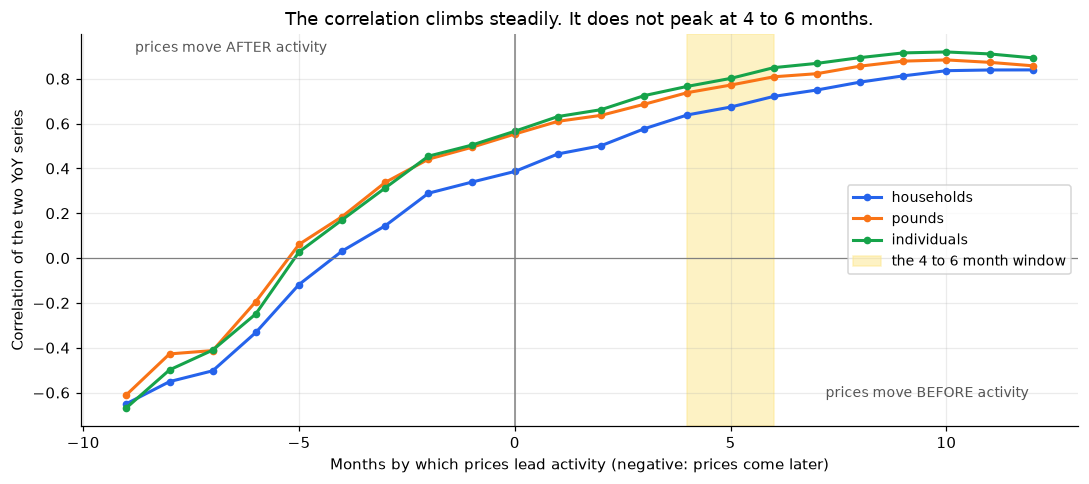

,n,households,pounds,individuals
lag,,,,
-6,36,-0.332,-0.194,-0.249
-3,39,0.144,0.338,0.313
-1,41,0.339,0.494,0.504
0,42,0.386,0.553,0.566
1,42,0.465,0.610,0.631
3,42,0.577,0.686,0.725
5,42,0.674,0.772,0.801
6,42,0.721,0.809,0.849
9,42,0.813,0.878,0.915


In [9]:
rows = []
for lag in range(-9, 13):
    d = yoy[METRICS].join(cpi_yoy.shift(lag).rename("cpi")).dropna()
    rows.append({"lag": lag, "n": len(d), **{m: d[m].corr(d["cpi"]) for m in METRICS}})
leads = pd.DataFrame(rows).set_index("lag")

fig, ax = plt.subplots(figsize=(10, 4.5))
for m in METRICS:
    ax.plot(leads.index, leads[m], marker="o", ms=4, lw=2, color=COLORS[m], label=m)
ax.axvspan(4, 6, color="#fde68a", alpha=0.5, label="the 4 to 6 month window")
ax.axvline(0, color="grey", lw=1)
ax.axhline(0, color="grey", lw=0.8)
ax.text(-8.8, 0.92, "prices move AFTER activity", fontsize=9, color="#555")
ax.text(7.2, -0.62, "prices move BEFORE activity", fontsize=9, color="#555")
ax.set_xlabel("Months by which prices lead activity (negative: prices come later)")
ax.set_ylabel("Correlation of the two YoY series")
ax.set_title("The correlation climbs steadily. It does not peak at 4 to 6 months.")
ax.legend(fontsize=9, loc="center right")
plt.tight_layout()
plt.show()

leads.loc[[-6, -3, -1, 0, 1, 3, 5, 6, 9, 10, 11, 12]].round(3)

**F:** The correlation rises steadily from minus 0.33 at a 6-month lead to 0.39 at lag 0
and 0.84 at lag 10 (households). It does not peak at 4 to 6 months. It peaks at 10 to 11,
and it is already 0.34 to 0.50 when prices move one month *after* activity.

This is the pattern two one-time declines produce. Prices fell first and activity growth
fell later, so sliding one series along the other gives a better match the further it is
slid, up to the gap between the two declines. The "lag" measures that gap. It does not
measure how long a household takes to respond.

**W:** Step 10b found a peak at 5 to 6 because of the two things shown above, neither of
which is about timing: the sites control is nearly a copy of lagged CPI, and the spread
of the CPI series changes with the lag.

## C. Adding controls

**Q:** What else moved in the same months, and does the price effect survive it?

**D:** Added two controls to the Step 10b model at lag 5, the lag it identified as the
peak:

- **SNAP benefit per case**, statewide, year-over-year. From the Minnesota SNAP dashboard,
  now in the repo (`qkit.snap()`). The dashboard records the end of emergency allotments
  in April 2023.
- **A time trend**, in years. It absorbs any steady drift that prices and activity share.

All standard errors are HAC with a 12-month window.

Controls that are not available: monthly unemployment by county (the LAUS files in the
repo are annual) and any measure of food bank supply.

In [10]:
SPECS = {
    "A  Step 10b: CPI + sites": ["cpi", "sites"],
    "B  + SNAP benefit": ["cpi", "sites", "snap"],
    "C  + SNAP benefit + time trend": ["cpi", "sites", "snap", "trend"],
    "D  + time trend only": ["cpi", "sites", "trend"],
}
d = data_at(5)
rows = []
for m in METRICS:
    for name, cols in SPECS.items():
        f = hac_fit(d[m], d[cols], maxlags=12)
        rows.append({"metric": m, "model": name, "R2": f.rsquared,
                     "CPI coef": f.params["cpi"], "CPI p": f.pvalues["cpi"],
                     "SNAP coef": f.params.get("snap", np.nan),
                     "SNAP p": f.pvalues.get("snap", np.nan)})
controls = pd.DataFrame(rows).set_index(["metric", "model"])
controls

R2  CPI coef  CPI p  SNAP coef  SNAP p
metric      model                                                                   
households  A  Step 10b: CPI + sites       0.494     4.713  0.000        NaN     NaN
            B  + SNAP benefit              0.745     3.283  0.000     -0.530   0.000
            C  + SNAP benefit + time trend 0.746     2.925  0.030     -0.518   0.000
            D  + time trend only           0.534     2.233  0.074        NaN     NaN
pounds      A  Step 10b: CPI + sites       0.628     3.517  0.000        NaN     NaN
            B  + SNAP benefit              0.721     2.889  0.000     -0.232   0.003
            C  + SNAP benefit + time trend 0.726     2.300  0.001     -0.214   0.003
            D  + time trend only           0.656     2.015  0.002        NaN     NaN
individuals A  Step 10b: CPI + sites       0.667     5.322  0.000        NaN     NaN
            B  + SNAP benefit              0.806     4.132  0.000     -0.440   0.000
            C  + SNAP benefit + time trend 0.815     2.894  0.008     -0.401   0.001
            D  + time trend only           0.712     2.358  0.043        NaN     NaN

**F:** The SNAP cut explains a large share of what the price variable was credited with.

| | households | pounds | individuals |
|---|---|---|---|
| R², prices and sites only | 0.49 | 0.63 | 0.67 |
| R², with SNAP added | 0.75 | 0.72 | 0.81 |
| Price coefficient, before | 4.71 | 3.52 | 5.32 |
| Price coefficient, with SNAP and trend | 2.93 | 2.30 | 2.89 |
| Change | minus 38% | minus 35% | minus 46% |

The SNAP coefficient for households is minus 0.53: a 10% cut in the benefit per case goes
with 5.3 points more growth in households served. It is weakest for pounds (minus 0.23),
which fits the finding in Step 11 that pounds is limited by supply.

**W:** The SNAP series is one event, so its p-value is no more trustworthy than the price
one (section A). What this table shows is that the two explanations compete for the same
months, and the statewide series cannot separate them.

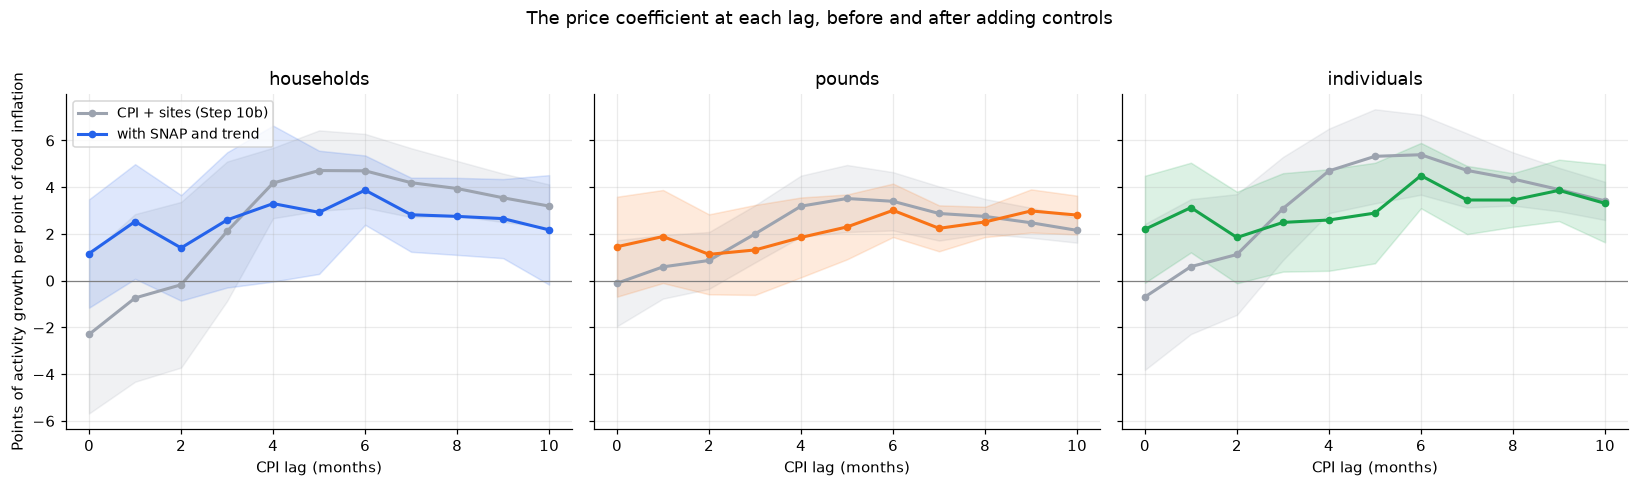

metric,households,pounds,individuals
lag,,,
0,1.160,1.450,2.200
1,2.530,1.890,3.130
2,1.400,1.130,1.850
3,2.600,1.310,2.490
4,3.300,1.850,2.600
5,2.930,2.300,2.890
6,3.870,3.010,4.500
7,2.820,2.240,3.450
8,2.750,2.510,3.450


In [11]:
FULL = ["cpi", "sites", "snap", "trend"]
rows = []
for m in METRICS:
    for lag in range(0, 11):
        d = data_at(lag)
        for label, cols in [("CPI + sites (Step 10b)", ["cpi", "sites"]),
                            ("with SNAP and trend", FULL)]:
            f = hac_fit(d[m], d[cols], maxlags=12)
            lo, hi = f.conf_int().loc["cpi"]
            rows.append({"metric": m, "lag": lag, "model": label, "coef": f.params["cpi"],
                         "lo": lo, "hi": hi, "p": f.pvalues["cpi"]})
profile = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, m in zip(axes, METRICS):
    for label, color in [("CPI + sites (Step 10b)", "#9ca3af"), ("with SNAP and trend", COLORS[m])]:
        g = profile[(profile["metric"] == m) & (profile["model"] == label)]
        ax.plot(g["lag"], g["coef"], marker="o", ms=4, lw=2, color=color, label=label)
        ax.fill_between(g["lag"], g["lo"], g["hi"], color=color, alpha=0.15)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(m)
    ax.set_xlabel("CPI lag (months)")
axes[0].set_ylabel("Points of activity growth per point of food inflation")
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("The price coefficient at each lag, before and after adding controls", y=1.02)
plt.tight_layout()
plt.show()

(profile[profile["model"] == "with SNAP and trend"]
    .pivot(index="lag", columns="metric", values="coef")[METRICS].round(2))

**F:** With controls, the price coefficient is positive at every lag from 0 to 10 and sits
between 1.2 and 3.9 for households. The shaded intervals overlap at every lag. There is
no peak. The rise from lag 0 to lag 5 in the grey line, which was the basis for "4 to 6
months", is gone.

**W:** A flat profile does not mean prices act at every lag. It means year-over-year data
cannot say when they act. Section D uses a method that can.

## D. A cleaner test of timing: month-to-month changes

**Q:** If year-over-year data cannot show timing, what can?

**D:** Switched from year-over-year changes to month-to-month changes in the log of each
series. Month-of-year dummies remove the seasonal pattern. This has two advantages:

- Monthly price changes at different lags are nearly unrelated (largest correlation
  0.44, against 0.96 to 0.99 for the year-over-year lags in Step 10b). So lags 0 to 6 can
  all go in **one** model. This is the distributed-lag model the Q4 README asks for.
- A shared slow trend drops out, because each month is compared with the one before.

HAC window of 3 months, which is enough here because monthly changes do not overlap.

largest correlation between any two CPI lags: 0.44
a typical monthly price change: 0.38%


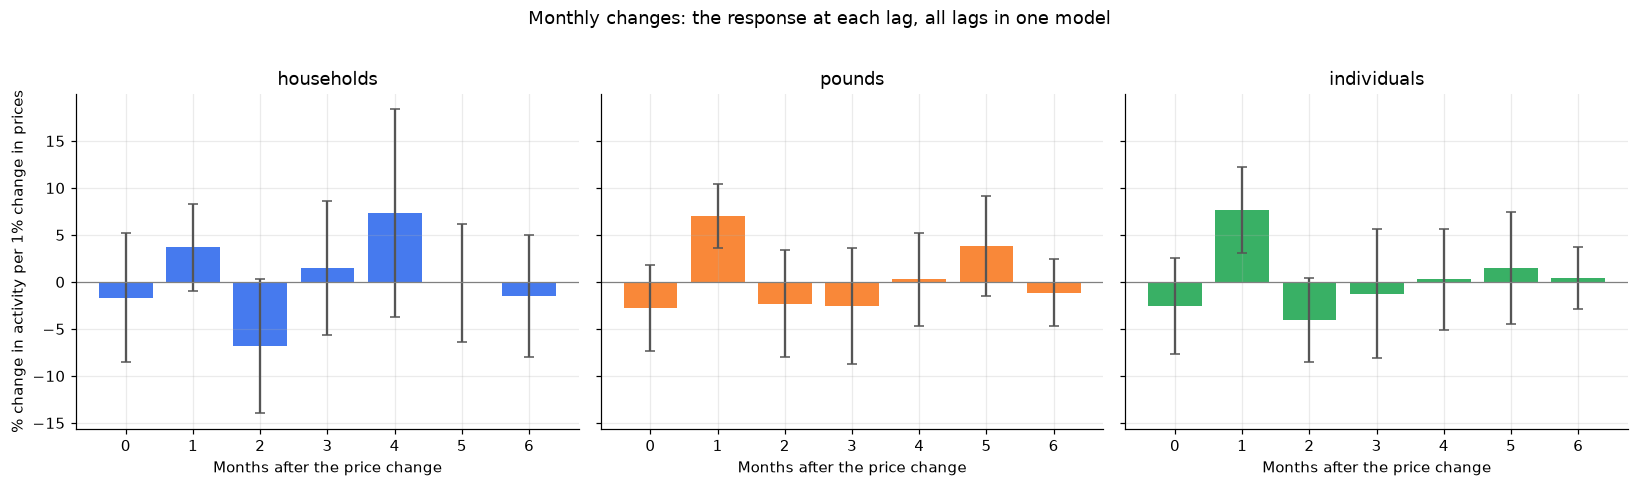

metric,households,pounds,individuals
lag,,,
0,-1.680,-2.750,-2.570
1,3.670,7.010,7.670
2,-6.850,-2.330,-4.040
3,1.500,-2.600,-1.240
4,7.310,0.270,0.260
5,-0.100,3.820,1.480
6,-1.510,-1.150,0.420


metric,households,pounds,individuals
lag,,,
0,0.633,0.242,0.322
1,0.123,0.000,0.001
2,0.060,0.424,0.079
3,0.679,0.408,0.722
4,0.195,0.914,0.923
5,0.974,0.162,0.627
6,0.648,0.527,0.802


,n,sum of lags 0-6,se,p (sum = 0),p (all lags = 0)
metric,,,,,
households,46,2.349,2.343,0.316,0.038
pounds,46,2.278,1.595,0.153,0.001
individuals,46,1.981,1.853,0.285,0.001


In [12]:
# Month-to-month changes. Here the CPI lags are nearly unrelated to each other, so all of
# them can go into one model. That is a real distributed-lag model.
LAGS = list(range(0, 7))
dlog = np.log(st[METRICS]).diff()
dcpi = np.log(cpi).diff()

X = pd.concat([dcpi.shift(k).rename(f"cpi_lag{k}") for k in LAGS]
              + [np.log(st["n_sites"]).diff().rename("sites")], axis=1)
month = pd.get_dummies(X.index.month, prefix="month", drop_first=True, dtype=float)
month.index = X.index
X = pd.concat([X, month], axis=1)
names = [f"cpi_lag{k}" for k in LAGS]
print("largest correlation between any two CPI lags:",
      round(X[names].corr().where(~np.eye(len(LAGS), dtype=bool)).abs().max().max(), 2))
print(f"a typical monthly price change: {100 * dcpi.loc['2022-01-01':].abs().median():.2f}%")

rows, summary = [], []
for m in METRICS:
    d = pd.concat([dlog[m], X], axis=1).dropna()
    f = hac_fit(d[m], d.drop(columns=m), maxlags=3)
    ci = f.conf_int()
    for k in LAGS:
        n = f"cpi_lag{k}"
        rows.append({"metric": m, "lag": k, "coef": f.params[n], "lo": ci.loc[n, 0],
                     "hi": ci.loc[n, 1], "p": f.pvalues[n]})
    total = f.t_test(" + ".join(names) + " = 0")
    joint = f.f_test(", ".join(f"{n} = 0" for n in names))
    summary.append({"metric": m, "n": int(f.nobs),
                    "sum of lags 0-6": float(total.effect[0]), "se": float(total.sd[0][0]),
                    "p (sum = 0)": float(total.pvalue),
                    "p (all lags = 0)": float(joint.pvalue)})
monthly = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, m in zip(axes, METRICS):
    g = monthly[monthly["metric"] == m]
    ax.bar(g["lag"], g["coef"], color=COLORS[m], alpha=0.85,
           yerr=[g["coef"] - g["lo"], g["hi"] - g["coef"]], capsize=3, ecolor="#555")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(m)
    ax.set_xlabel("Months after the price change")
axes[0].set_ylabel("% change in activity per 1% change in prices")
fig.suptitle("Monthly changes: the response at each lag, all lags in one model", y=1.02)
plt.tight_layout()
plt.show()

display(monthly.pivot(index="lag", columns="metric", values="coef")[METRICS].round(2))
display(monthly.pivot(index="lag", columns="metric", values="p")[METRICS].round(3))
pd.DataFrame(summary).set_index("metric")

**F:** The only lag that stands out is **one month**.

| Lag 1 | households | pounds | individuals |
|---|---|---|---|
| Coefficient | +3.7 | +7.0 | +7.7 |
| p-value | 0.12 | below 0.001 | 0.001 |

There are 21 tests here (7 lags, 3 metrics), so a fair threshold is 0.05 / 21 = 0.0024.
Pounds and individuals at lag 1 pass it. Nothing else does. Lags 4, 5 and 6 are
indistinguishable from zero in all three metrics.

Lag 2 is negative in all three metrics (minus 6.9, minus 2.3, minus 4.0). Added up over
lags 0 to 6, the net effect is about +2 and cannot be told apart from zero (p = 0.15 to
0.32).

**In words:** a rise in food prices is followed one month later by more pounds distributed
and more individuals served, and the month after that gives part of it back. That looks
more like visits moving earlier than like lasting extra demand.

**W:** Three reasons to hold this loosely.

- 46 months and 19 parameters. The intervals are wide.
- Households does not show it (p = 0.12), and households is our stand-in for visits.
- A typical monthly price change is a fraction of a percent, so a coefficient of 7 is a
  small movement in activity. It would not be visible on a chart.

## E. Counties: cost, or metro?

**Q:** The county cost comparison near the end of `q4_exploration` (the cell that draws the
Minnesota map) found that higher-cost counties have more activity per food-insecure
person (3.19 against 2.14). The advisor asked for the split by metro and non-metro. Is the cost
difference really a metro difference?

**D:** Used the 2024 county cross-section, 86 counties (Wilkin has no activity). Metro
means USDA rural-urban codes 1 to 3, the same rule as `src/eda.py`. Compared two
measures:

- **households per food-insecure person**, as in the county cost comparison
- **the residual from Q1**: activity against need with county size removed (the residual
  of log activity on log food-insecure persons, averaged over the three metrics)

Groups are compared on medians with a Mann-Whitney test, because the ratio has a few very
large values.

In [13]:
cy = qkit.county_year([2024], food_shelf_only=True).merge(
    qkit.covariates([2024])[["fips", "population"]], on="fips", how="left")
cy = cy[cy["households"] > 0].copy()          # Wilkin has no activity

cy["metro"] = np.where(cy["rucc_2023"] <= 3, "metro", "non-metro")     # USDA codes 1-3
cy["cost_group"] = np.where(cy["cost_per_meal"] > cy["cost_per_meal"].median(),
                            "higher cost", "lower cost")

# Activity relative to need with county size removed: the residual from Q1
for m in METRICS:
    cy[f"resid_{m}"] = smf.ols(f"np.log({m}) ~ np.log(fi_persons)", data=cy).fit().resid
cy["resid"] = cy[[f"resid_{m}" for m in METRICS]].mean(axis=1)

print(f"{len(cy)} counties, median cost per meal ${cy['cost_per_meal'].median():.2f}")
display(pd.crosstab(cy["cost_group"], cy["metro"], margins=True))
(cy[["cost_per_meal", "rucc_2023", "population", "fi_persons", "households_per_fi"]]
   .corr(method="spearman").round(2).loc[["cost_per_meal"]])

86 counties, median cost per meal $3.79


metro,metro,non-metro,All
cost_group,,,
higher cost,22,20,42
lower cost,5,39,44
All,27,59,86


,cost_per_meal,rucc_2023,population,fi_persons,households_per_fi
cost_per_meal,1.000,-0.580,0.480,0.430,0.200


In [14]:
def compare(by):
    """Mean and median of both measures for each group, with a test on the medians."""
    out = []
    for measure, label in [("households_per_fi", "households per FI person"),
                           ("resid", "residual (size removed)")]:
        g = cy.groupby(by)[measure]
        a, b = [v for _, v in g]
        row = {"measure": label}
        for name, values in g:
            row[f"{name}: n"] = len(values)
            row[f"{name}: mean"] = values.mean()
            row[f"{name}: median"] = values.median()
        row["p (Mann-Whitney)"] = sp.mannwhitneyu(a, b).pvalue
        out.append(row)
    return pd.DataFrame(out).set_index("measure")

display(compare("cost_group"))
display(compare("metro"))
(cy.groupby(["metro", "cost_group"])[["households_per_fi", "resid"]]
   .agg(["count", "mean", "median"]).round(3))

,higher cost: n,higher cost: mean,higher cost: median,lower cost: n,lower cost: mean,lower cost: median,p (Mann-Whitney)
measure,,,,,,,
households per FI person,42,3.192,2.433,44,2.144,1.934,0.158
residual (size removed),42,0.037,-0.054,44,-0.035,-0.110,0.701


,metro: n,metro: mean,metro: median,non-metro: n,non-metro: mean,non-metro: median,p (Mann-Whitney)
measure,,,,,,,
households per FI person,27,3.200,2.347,59,2.407,1.906,0.077
residual (size removed),27,0.032,-0.034,59,-0.015,-0.109,0.602


households_per_fi              resid              
                                  count  mean median count   mean median
metro     cost_group                                                    
metro     higher cost                22 3.521  2.746    22  0.088  0.088
          lower cost                  5 1.788  1.985     5 -0.216 -0.091
non-metro higher cost                20 2.830  1.837    20 -0.020 -0.085
          lower cost                 39 2.189  1.906    39 -0.012 -0.111

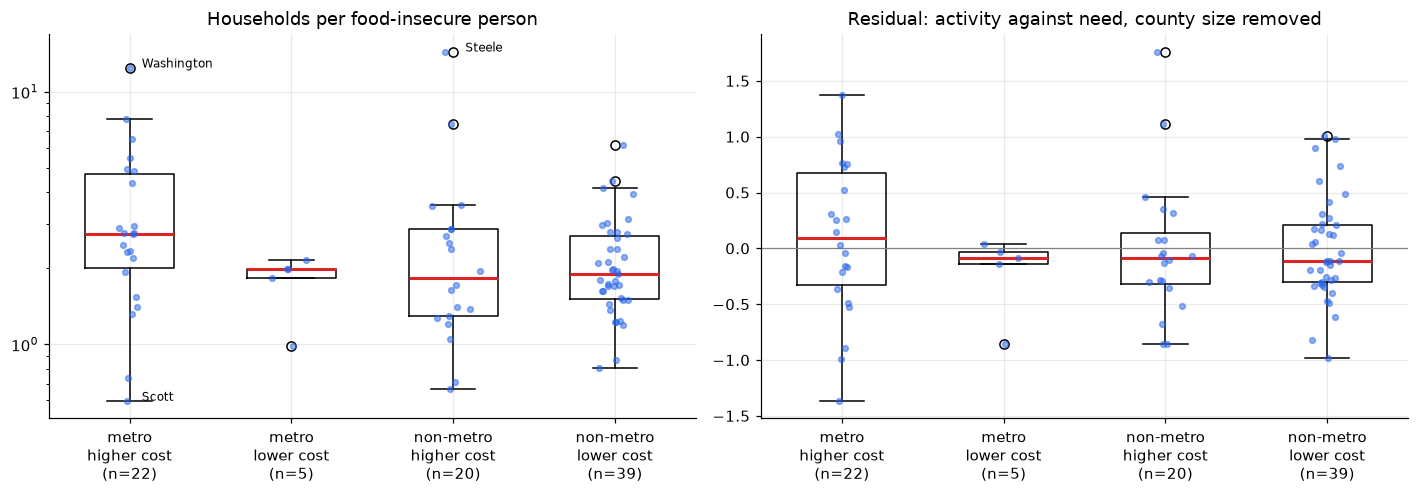

In [15]:
order = [("metro", "higher cost"), ("metro", "lower cost"),
         ("non-metro", "higher cost"), ("non-metro", "lower cost")]
labels = [f"{a}\n{b}\n(n={((cy.metro == a) & (cy.cost_group == b)).sum()})" for a, b in order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col, title, log in [
        (axes[0], "households_per_fi", "Households per food-insecure person", True),
        (axes[1], "resid", "Residual: activity against need, county size removed", False)]:
    groups = [cy.loc[(cy.metro == a) & (cy.cost_group == b), col] for a, b in order]
    ax.boxplot(groups, widths=0.55, medianprops={"color": "#dc2626", "lw": 2})
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(labels)     # set separately: works on every matplotlib version
    for i, g in enumerate(groups, start=1):
        ax.scatter(np.random.default_rng(i).normal(i, 0.05, len(g)), g, s=14, alpha=0.5,
                   color="#2563eb", zorder=3)
    if log:
        ax.set_yscale("log")
    else:
        ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(title)
for name in ["Steele", "Washington", "Scott"]:
    r = cy[cy["county_name"] == name].iloc[0]
    i = order.index((r["metro"], r["cost_group"])) + 1
    axes[0].annotate(name, (i, r["households_per_fi"]), xytext=(8, 0),
                     textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
cy["cost_z"] = (cy["cost_per_meal"] - cy["cost_per_meal"].mean()) / cy["cost_per_meal"].std()
cy["is_metro"] = (cy["metro"] == "metro").astype(int)
cy["log_hh_per_fi"] = np.log(cy["households_per_fi"])

rows = []
for outcome, formula in [
        ("log households per FI", "log_hh_per_fi ~ cost_z"),
        ("log households per FI", "log_hh_per_fi ~ is_metro"),
        ("log households per FI", "log_hh_per_fi ~ cost_z + is_metro"),
        ("log households per FI", "log_hh_per_fi ~ cost_z + is_metro + np.log(fi_persons)"),
        ("residual", "resid ~ cost_z + is_metro")]:
    f = smf.ols(formula, data=cy).fit(cov_type="HC3")
    rows.append({"outcome": outcome, "model": formula.split("~")[1].strip(), "R2": f.rsquared,
                 "cost coef": f.params.get("cost_z", np.nan), "cost p": f.pvalues.get("cost_z", np.nan),
                 "metro coef": f.params.get("is_metro", np.nan),
                 "metro p": f.pvalues.get("is_metro", np.nan)})
pd.DataFrame(rows).set_index(["outcome", "model"])

R2  cost coef  cost p  metro coef  metro p
outcome               model                                                                               
log households per FI cost_z                                 0.034      0.111   0.174         NaN      NaN
                      is_metro                               0.031        NaN     NaN       0.226    0.140
                      cost_z + is_metro                      0.040      0.074   0.448       0.130    0.493
                      cost_z + is_metro + np.log(fi_persons) 0.065      0.053   0.562       0.017    0.930
residual              cost_z + is_metro                      0.003      0.030   0.719       0.007    0.970

**F:** The cost split and the metro split are largely the same split.

- 22 of the 27 metro counties are in the higher-cost group. 39 of the 44 lower-cost
  counties are non-metro. Cost per meal and the rural-urban code have a correlation of
  minus 0.58.
- The gap found in the cost comparison is in the **means**: 3.19 against 2.14. The medians are 2.43
  against 1.93, and the difference is not significant (p = 0.16). Three counties pull the
  mean up: Steele (14.4), Washington (12.5) and Olmsted (7.8).
- Metro against non-metro: medians 2.35 against 1.91, p = 0.08. Suggestive, not
  established.
- **Inside the non-metro counties, cost makes no difference**: medians 1.84 (higher cost)
  and 1.91 (lower cost).
- Once county size is removed, nothing is left. The residual does not differ by cost
  (p = 0.70) or by metro status (p = 0.60), and no regression explains more than 7% of
  the variation.

**In words:** counties where food costs more do not get more food shelf activity for their
level of need. What the cost comparison picked up was a few large counties with very high activity,
most of them metro.

**W:** `cost_per_meal` is an annual county estimate from Feeding America, modelled, not
measured. And the metro lower-cost group has only 5 counties, so nothing can be said
about it.

This matches Q1, which found that distance, rural code, vehicle access and SNAP share
together explain 3% of the same residual.

## F. Does "households per food-insecure person" carry the Q1 caveat?

**Q:** Q1 attached two caveats to this measure. Do they apply to how Q4 uses it?

**D:** Checked each caveat against the county cost comparison.

In [17]:
# Caveat 2 from Q1, checked on the 2024 data used here
fit = smf.ols("np.log(households) ~ np.log(fi_persons)", data=cy).fit(cov_type="HC3")
lo, hi = fit.conf_int().loc["np.log(fi_persons)"]
print(f"slope of log(households) on log(fi_persons): {fit.params.iloc[1]:.2f}  "
      f"(95% interval {lo:.2f} to {hi:.2f})")
print(f"a county with 10x the food-insecure people records {10 ** fit.params.iloc[1] / 10:.2f}x "
      "the households per food-insecure person")
top = cy.nlargest(3, "households_per_fi")["households_per_fi"].sum() / cy["households_per_fi"].sum()
print(f"the 3 highest counties hold {top:.0%} of the total of the ratio across {len(cy)} counties")
cy[["households_per_fi"]].describe().T.round(2)

slope of log(households) on log(fi_persons): 1.13  (95% interval 1.01 to 1.25)
a county with 10x the food-insecure people records 1.34x the households per food-insecure person
the 3 highest counties hold 15% of the total of the ratio across 86 counties


,count,mean,std,min,25%,50%,75%,max
households_per_fi,86.000,2.660,2.210,0.600,1.500,1.990,2.840,14.440


**F:** One applies and one does not.

| Q1 caveat | Applies to Q4? | Why |
|---|---|---|
| 1. Built-in negative tilt | **No** | The tilt arises when the ratio is set against `fi_rate`, because `fi_persons` is under the line in one and over it in the other. The cost comparison sets the ratio against `cost_per_meal`, which does not contain `fi_persons`. |
| 2. The ratio still carries county size | **Yes** | The slope of log households on log food-insecure persons is 1.13 (95% interval 1.01 to 1.25). A county with 10 times the food-insecure people records 1.34 times the households per food-insecure person. Higher-cost counties are larger (correlation 0.48 with population), so part of their higher ratio is size. |

Two more things to state whenever the measure is used:

- **It is skewed.** Mean 2.66, median 1.99, maximum 14.4. Report medians, or work in logs.
- **The unit is household-months.** A household is counted once in each month it is served,
  and the count is added up over the year. A value of 3 means three household-months of
  service per food-insecure person per year. It does not mean three households.

**W:** The slope here (1.13) is lower than the 1.18 in the Q1 notebook because Q4 uses
food-shelf-like sites only and Q1 uses all sites. Both are above 1.

**Recommendation:** for any comparison across counties, use the Q1 residual in place of
the ratio. It answers the same question, "how much activity relative to need", with county
size already removed.

## G. What this means

### Answers to the four Q4 questions, as the evidence stands

| Q4 asks | Supported answer |
|---|---|
| Do more people arrive when prices rise? | Activity grew fastest during and just after the 2022 to 2023 inflation. The largest move, a 20% jump in March 2023, is a step and not a gradual rise, which points to an event. The SNAP benefit cut and a rise in reporting sites fall in the same months, and statewide data cannot separate the three. |
| At once, or after a delay? | Not after 4 to 6 months. Where a response shows, it is at about one month. |
| In all three metrics? | In pounds and individuals. Not clearly in households. |
| What cycles do prices not explain? | The seasonal pattern in `q4_exploration` stands (the index built from activity levels): an October peak, a January or February low, a swing of about 20%. Nothing here changes it. |

**Suggested headline:** *Food shelf activity grew fastest during the 2022 to 2023
inflation, but a cut in SNAP benefits happened at the same time, and statewide data cannot
separate the two. Where a price response can be seen, it arrives within a month, not
after four to six.*

### Can SNAP be used in Q4, and does that answer Q5?

Yes to the first, no to the second.

| | Q4 | Q5 |
|---|---|---|
| Role of SNAP | A control. Something else that moved, to be held fixed. | The subject. |
| Data | One statewide series | 79 county units |
| Where the evidence comes from | Change over time | Differences between counties in how exposed they were to the cut |

The two are linked, and the link runs one way. **Q5 can remove prices completely.** Every
county faces the same Midwest price index in a given month, so month dummies in a county
model absorb it. **Q4 cannot remove SNAP completely**, because a statewide series has no
counties to compare.

So the order matters:

1. Do Q5 first. Estimate the SNAP effect from county exposure, with month dummies.
2. Come back to Q4. Take the SNAP effect out of the statewide series, then look at what
   prices explain in what is left.

That also settles the item on the team agenda, "who claims 2023". Q5 claims what county
exposure can explain. Q4 gets the rest.

### Corrections to `q4_exploration.ipynb`

| Where | Change |
|---|---|
| Top cell, "Bottom line so far" | Replace the 4 to 6 month claim with the headline above |
| Step 2 | It finds the base and `_fs` columns identical and concludes either can be used. They are identical only because `county_month(food_shelf_only=True)` overwrites the base columns with the `_fs` ones. Without that flag they differ by about 7% of pounds. No result changes. |
| Step 10b | Mark as superseded by sections A to D here, the way Step 10a is marked |
| Step 12 | The "CPI adds 19% to 28% to R²" figure is from the model without SNAP. With SNAP in the model the question needs asking again. |
| County cost comparison (the map cell) | Replace the comparison of means with section E |

### Still to do

- The Minneapolis-St. Paul CPI series (`CUUSA211SAF11`) as a robustness check, as the
  README asks.
- Move the numbers that will go on slides into `questions/q4_food_prices/analysis.py`.
- Fill in the download date for the CPI file in `docs/DATA_SOURCES.md`.